# Data Challenge 2026–2027 · EasyVista — SLA prediction in ITSM
## Exploratory analysis

The two tasks of the challenge:
1. **Classification**: will the ticket's SLA be violated? (`viol`)
2. **Regression**: how long will it take to resolve the ticket? (`res_hours`)

Contents:
1. Loading and cleaning
2. Target distribution
3. Missing values: share per feature and by target class
4. Feature statistics and distributions: descriptive statistics, skewness, kurtosis
5. Outliers: boxplots and IQR rule
6. Correlation between features
7. Sanity checks: errors per feature and their distribution across target classes
8. Additional analysis: volume over time, targets by subgroup, time of submission, submitters, link between the two targets
9. Key takeaways for the modelling

Feature engineering and models are in `SLA_baseline_v2.ipynb`.

**Requirements:** `pandas numpy scipy matplotlib holidays`

### Setup (Colab)
Run these two cells first. The first one writes `prep.py` (shared data preparation) into the working folder, so you do not need to upload it. The second installs the missing libraries and asks you to upload `raw_EV_data_challenge.csv`.

In [1]:
%%writefile prep.py
"""Shared data preparation for the EasyVista Data Challenge (SLA prediction).

Usage:
    from prep import load_data, CAT_CREATE, NUM_CREATE, ...
    df = load_data("raw_EV_data_challenge.csv")

Changes vs. the first version (see the work guide, section 3):
  * calendar features use Paris local time instead of UTC                     (issue 5)
  * `sla_nominal`: deadline length known at submission, replaces the
    recorded `sla_real_hours`, which looks recomputed during the ticket life (issue 1)
  * `open_recent_30d`: alternative load counter on the last 30 days only (issue 3).
    The rolling CV prefers the original cumulative counter, so it stays in NUM_CREATE
    and the 30-day version is kept in RECENT_LOAD for the ablation
  * `never_closed` flag, to report metrics with and without these tickets    (issue 4)
"""
import numpy as np
import pandas as pd
import holidays

DATE_COLS = ["SUBMIT_DATE_UT", "MAX_RESOLUTION_DATE_UT", "END_DATE_UT"]
VALID_START = pd.Timestamp("2024-01-01")
TEST_START = pd.Timestamp("2024-04-01")
REG_TEST_END = pd.Timestamp("2024-08-01")   # margin against censoring for the "plain" regression test
LOCAL_TZ = "Europe/Paris"                   # timestamps are UTC; business hours follow Paris time
LOAD_WINDOW_DAYS = 30                       # look-back window for the load feature

# Features known when the ticket is created (no leakage)
CAT_CREATE = ["SD_CATALOG_PATH_EN", "URGENCY_VALUE", "IMPACT_VALUE", "SLA_DELAY", "REQUEST_ORIGIN", "SUBMITTED_BY_ID"]
NUM_CREATE = ["sla_nominal", "hour", "dow", "month", "is_weekend", "is_holiday", "off_hours",
              "submitter_missing", "open_tickets_at_submit", "open_same_type_at_submit",
              "arrivals_24h", "arrivals_7d", "submitter_prev_tickets"]

# Kept only for ablations
LEAK_SUSPECT = ["sla_real_hours"]                                  # recorded deadline length (likely leak)
RECENT_LOAD = ["open_recent_30d", "open_recent_30d_same_type"]     # 30-day load counters (no time trend)
CUMULATIVE_LOAD = ["open_tickets_at_submit", "open_same_type_at_submit"]  # in NUM_CREATE; trends with time

# "Oracle" features, known only after the ticket is closed (upper bound, never for production)
CAT_ORACLE = ["LAST_DONE_BY_ID", "STATUS_EN"]
NUM_ORACLE = ["nb_actions"]

MIN_HOURS = 1 / 60  # 1 minute: minimum duration, avoids log(0) in survival models


def load_data(path):
    df = pd.read_csv(path, sep=";", na_values=["NULL"])
    for c in DATE_COLS:
        df[c] = pd.to_datetime(df[c]).astype("datetime64[ns]")
    df = df.sort_values("SUBMIT_DATE_UT").reset_index(drop=True)

    # Impossible closing dates (before submission, e.g. 1900-01-01) -> missing
    df.loc[df["END_DATE_UT"] < df["SUBMIT_DATE_UT"], "END_DATE_UT"] = pd.NaT
    extract = max(df["SUBMIT_DATE_UT"].max(), df["END_DATE_UT"].max())
    df.attrs["extract_date"] = extract

    # Targets, as known at the extraction date
    df["viol"] = viol_as_of(df, extract)
    df["res_hours"] = (df["END_DATE_UT"] - df["SUBMIT_DATE_UT"]).dt.total_seconds() / 3600
    df["never_closed"] = df["END_DATE_UT"].isna().astype(int)

    t = df["SUBMIT_DATE_UT"]
    df["split"] = np.where(t < VALID_START, "train", np.where(t < TEST_START, "valid", "test"))
    _add_features(df)
    return df


def viol_as_of(df, cutoff):
    """SLA-violation label as it would have been known at date `cutoff`.
    1   = deadline passed without closure (or closed after the deadline), known if deadline < cutoff
    0   = closed within the deadline, known if closure <= cutoff
    NaN = still unknown at that date (or ticket without SLA)."""
    end, dl = df["END_DATE_UT"], df["MAX_RESOLUTION_DATE_UT"]
    out = pd.Series(np.nan, index=df.index)
    ok0 = dl.notna() & end.notna() & (end <= dl) & (end <= cutoff)
    ok1 = dl.notna() & (dl < cutoff) & (end.isna() | (end > dl))
    out[ok0] = 0.0
    out[ok1] = 1.0
    return out


def duration_as_of(df, cutoff):
    """Duration in hours and event indicator as known at date `cutoff`.
    Tickets not closed by `cutoff` are right-censored at (cutoff - submission)."""
    end = df["END_DATE_UT"]
    observed = end.notna() & (end <= cutoff)
    stop = end.where(observed, cutoff)
    dur = ((stop - df["SUBMIT_DATE_UT"]).dt.total_seconds() / 3600).clip(lower=MIN_HOURS)
    return dur, observed.astype(int)


def _open_recent(sub_ns, end_ns, window_ns):
    """For each ticket: how many tickets submitted in the previous `window_ns` are still open at its submission.
    Arrays must be sorted by submission time. Uses only information available at submission."""
    first = np.searchsorted(sub_ns, sub_ns - window_ns, side="left")
    before = np.searchsorted(sub_ns, sub_ns, side="left")
    out = np.empty(len(sub_ns), dtype=np.int64)
    for i in range(len(sub_ns)):
        out[i] = np.count_nonzero(end_ns[first[i]:before[i]] >= sub_ns[i])
    return out


def _add_features(df):
    t = df["SUBMIT_DATE_UT"]

    # Recorded deadline length (suspected leakage: kept only for ablations)
    df["sla_real_hours"] = (df["MAX_RESOLUTION_DATE_UT"] - t).dt.total_seconds() / 3600

    # Calendar features in Paris local time (handles daylight saving)
    loc = t.dt.tz_localize("UTC").dt.tz_convert(LOCAL_TZ).dt.tz_localize(None)
    df["hour"] = loc.dt.hour
    df["dow"] = loc.dt.dayofweek
    df["month"] = loc.dt.month
    df["is_weekend"] = (df["dow"] >= 5).astype(int)
    fr = holidays.France(years=range(loc.dt.year.min(), loc.dt.year.max() + 1))
    df["is_holiday"] = loc.dt.date.map(lambda d: d in fr).astype(int)
    df["off_hours"] = ((df["hour"] < 8) | (df["hour"] >= 18) | (df["is_weekend"] == 1)
                       | (df["is_holiday"] == 1)).astype(int)
    df["submitter_missing"] = df["SUBMITTED_BY_ID"].isna().astype(int)

    # Nominal deadline length, known at submission: median recorded length for the same
    # SLA_DELAY and hour of the week, estimated on the training period only
    # (a missing SLA_DELAY is treated as its own group: ~130 tickets have a deadline but no SLA_DELAY).
    # The median is robust to the ~9% of deadlines that are extended later on.
    df["hour_of_week"] = df["dow"] * 24 + df["hour"]
    tr = df["split"] == "train"
    by_slot = df[tr].groupby(["SLA_DELAY", "hour_of_week"], dropna=False)["sla_real_hours"].median().rename("_slot")
    by_delay = df[tr].groupby("SLA_DELAY", dropna=False)["sla_real_hours"].median().rename("_delay")
    nom = (df[["SLA_DELAY", "hour_of_week"]]
           .merge(by_slot, left_on=["SLA_DELAY", "hour_of_week"], right_index=True, how="left")
           .merge(by_delay, left_on="SLA_DELAY", right_index=True, how="left"))
    df["sla_nominal"] = nom["_slot"].fillna(nom["_delay"]).values   # fallback: median per SLA_DELAY
    # Diagnostic only (uses the recorded deadline): deadline clearly longer than the nominal one
    df["deadline_extended"] = ((df["sla_real_hours"] > 1.5 * df["sla_nominal"])
                               & (df["sla_real_hours"] - df["sla_nominal"] > 24)).astype(int)

    # System load: only information known at submission
    sub_ns = t.values.astype("datetime64[ns]").astype("int64")
    end_ns = df["END_DATE_UT"].values.astype("datetime64[ns]").astype("int64")
    end_ns = np.where(df["END_DATE_UT"].isna(), np.iinfo("int64").max, end_ns)  # never closed = open forever
    n_before = np.searchsorted(sub_ns, sub_ns, side="left")
    day = np.int64(24 * 3600 * 10**9)

    # Cumulative counters (all tickets ever opened and still open). They grow with time because
    # never-closed tickets pile up and the data starts at zero in Sep 2022, but the rolling CV
    # still prefers them to the 30-day version: keep them, and do not read their SHAP plot as a pure load effect
    df["open_tickets_at_submit"] = n_before - np.searchsorted(np.sort(end_ns), sub_ns, side="left")
    df["open_same_type_at_submit"] = 0
    # 30-day counters: only tickets submitted in the last LOAD_WINDOW_DAYS (the first month of data is a warm-up)
    win = LOAD_WINDOW_DAYS * day
    df["open_recent_30d"] = _open_recent(sub_ns, end_ns, win)
    df["open_recent_30d_same_type"] = 0
    for _, idx in df.groupby("SD_CATALOG_PATH_EN").groups.items():
        s, e = sub_ns[idx], end_ns[idx]
        df.loc[idx, "open_same_type_at_submit"] = np.searchsorted(s, s, side="left") - np.searchsorted(np.sort(e), s, side="left")
        df.loc[idx, "open_recent_30d_same_type"] = _open_recent(s, e, win)

    df["arrivals_24h"] = n_before - np.searchsorted(sub_ns, sub_ns - day, side="left")
    df["arrivals_7d"] = n_before - np.searchsorted(sub_ns, sub_ns - 7 * day, side="left")

    # Submitter history: number of tickets opened before this one (-1 = unknown submitter)
    df["submitter_prev_tickets"] = df.groupby("SUBMITTED_BY_ID").cumcount()
    df.loc[df["SUBMITTED_BY_ID"].isna(), "submitter_prev_tickets"] = -1


def prepare_cats(frame, cats, train_mask, min_count=20):
    """Categoricals as 'category' dtype (LightGBM/XGBoost); rare or unseen levels in train -> '__other__'."""
    X = frame.copy()
    for c in cats:
        s = X[c].astype("string").fillna("__missing__")
        vc = s[train_mask].value_counts()
        keep = set(vc[vc >= min_count].index)
        X[c] = pd.Categorical(s.where(s.isin(keep), "__other__"))
    return X


Overwriting prep.py


In [2]:
# Colab setup: install the libraries that Colab does not preinstall,
# then upload the CSV if it is not in the working folder yet (prep.py is written by the cell above).
!pip install -q catboost lifelines holidays
import os
if not os.path.exists("raw_EV_data_challenge.csv"):
    try:
        from google.colab import files
        print("Please upload raw_EV_data_challenge.csv")
        files.upload()
    except ImportError:
        print("Put raw_EV_data_challenge.csv next to the notebook.")
else:
    print("CSV found.")

CSV found.


In [3]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from scipy import stats

SEED = 42
DATA_PATH = "raw_EV_data_challenge.csv"

# palette (colorblind-safe, fixed order)
BLUE, ORANGE, AQUA, GRAY, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a85", "#e1e0d9"
INK = "#3d3d3a"  # text colour for annotations
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "figure.dpi": 110})
pd.set_option("display.width", 140)

## 1. Loading and cleaning

In [4]:
# All data preparation now lives in prep.py, so both notebooks use exactly the same
# targets and features. Keep the plotting cell of section 2 as it is.
from prep import (load_data, prepare_cats, CAT_CREATE, NUM_CREATE, CAT_ORACLE, NUM_ORACLE,
                  LEAK_SUSPECT, VALID_START, TEST_START, REG_TEST_END)

df = load_data(DATA_PATH)
EXTRACT_DATE = df.attrs["extract_date"]
t = df["SUBMIT_DATE_UT"]
print(df.shape, "| period:", t.min(), "->", t.max(), "| extraction date:", EXTRACT_DATE)
print("tickets with a violation label:", df.viol.notna().sum(),
      "| of which never closed and overdue:", (df.viol.notna() & (df.never_closed == 1)).sum())
print("violation rate:", round(df.viol.mean(), 3), "| closed tickets (regression):", df.res_hours.notna().sum())
print(df.groupby("split").agg(n=("REQUEST_ID", "size"), viol_rate=("viol", "mean"),
                              res_median_h=("res_hours", "median")).round(3).loc[["train", "valid", "test"]])


(64175, 35) | period: 2022-09-16 06:04:44 -> 2024-09-16 18:25:36.993000 | extraction date: 2024-09-16 18:31:03.483000
tickets with a violation label: 59925 | of which never closed and overdue: 924
violation rate: 0.259 | closed tickets (regression): 60911
           n  viol_rate  res_median_h
split                                
train  38402      0.260        17.194
valid   9312      0.242         8.118
test   16461      0.265         7.213


## 2. Target distribution

**SLA violation** (`viol`), defined only for tickets with an SLA (`MAX_RESOLUTION_DATE_UT` present):
- closed ticket → `viol = END_DATE > MAX_RESOLUTION_DATE`
- ticket **not closed** but with the deadline already passed at the extraction date → `viol = 1` (the SLA is certainly violated)
- ticket not closed with a future deadline → unknown label, excluded

**Resolution time** (`res_hours`): calendar hours between opening and closing; for the regression we use `log1p(res_hours)` because of the long tail. Tickets that are not closed are **right-censored** (see next steps: survival analysis).

,n,share_of_all
viol,,
met (0),44427,0.692
violated (1),15498,0.241
no label,4250,0.066


class balance among labelled tickets: 25.9% violated  ->  imbalance ratio 2.9 : 1
           n  violated
split                 
train  35803     0.260
valid   8792     0.242
test   15330     0.265


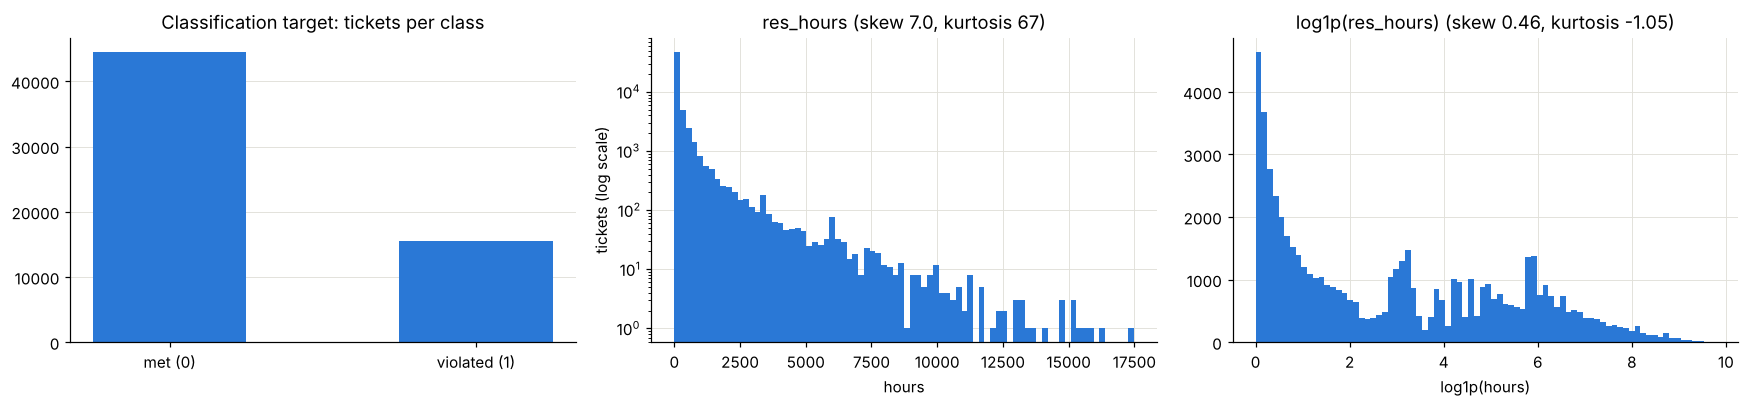

In [5]:
# Classification target: class balance (tickets with a known label only)
vc = df["viol"].map({0: "met (0)", 1: "violated (1)"}).fillna("no label").value_counts()
display(pd.DataFrame({"n": vc, "share_of_all": (vc / len(df)).round(3)}))
lab = df[df["viol"].notna()]
print(f"class balance among labelled tickets: {lab['viol'].mean():.1%} violated  ->  "
      f"imbalance ratio {(1 - lab['viol'].mean()) / lab['viol'].mean():.1f} : 1")
print(lab.groupby("split")["viol"].agg(n="size", violated="mean").round(3).loc[["train", "valid", "test"]])

# Regression target: raw hours vs log1p(hours)
closed = df[df["res_hours"].notna()]
y_raw, y_log = closed["res_hours"], np.log1p(closed["res_hours"])
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
axes[0].bar(["met (0)", "violated (1)"], lab["viol"].value_counts().sort_index().values, color=BLUE, width=0.5)
axes[0].set_title("Classification target: tickets per class"); axes[0].grid(axis="x", visible=False)
axes[1].hist(y_raw, bins=80, color=BLUE)
axes[1].set_title(f"res_hours (skew {y_raw.skew():.1f}, kurtosis {y_raw.kurt():.0f})")
axes[1].set_xlabel("hours"); axes[1].set_yscale("log"); axes[1].set_ylabel("tickets (log scale)")
axes[2].hist(y_log, bins=80, color=BLUE)
axes[2].set_title(f"log1p(res_hours) (skew {y_log.skew():.2f}, kurtosis {y_log.kurt():.2f})")
axes[2].set_xlabel("log1p(hours)")
plt.tight_layout(); plt.show()

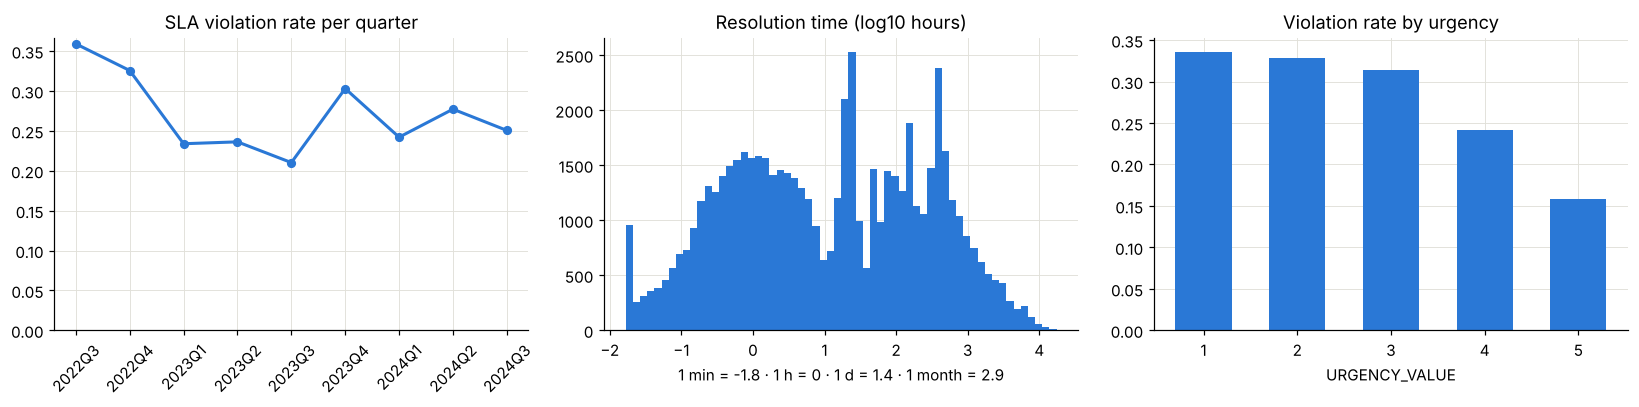

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))

q = df.dropna(subset=["viol"]).groupby(df.SUBMIT_DATE_UT.dt.to_period("Q"))["viol"].mean()
axes[0].plot(q.index.astype(str), q.values, color=BLUE, lw=2, marker="o", ms=5)
axes[0].set_title("SLA violation rate per quarter")
axes[0].set_ylim(0, None); axes[0].tick_params(axis="x", rotation=45)

axes[1].hist(np.log10(df.res_hours.dropna().clip(lower=1/60)), bins=60, color=BLUE)
axes[1].set_title("Resolution time (log10 hours)")
axes[1].set_xlabel("1 min = -1.8 · 1 h = 0 · 1 d = 1.4 · 1 month = 2.9")

u = df.dropna(subset=["viol"]).groupby("URGENCY_VALUE")["viol"].mean()
axes[2].bar(u.index.astype(str), u.values, color=BLUE, width=0.6)
axes[2].set_title("Violation rate by urgency"); axes[2].set_xlabel("URGENCY_VALUE")
plt.tight_layout(); plt.show()

**Reading.** 44,427 tickets met their SLA and 15,498 violated it; 4,250 (6.6%) have no label (no SLA, or still open with a future deadline). Among labelled tickets 25.9% are violated, an imbalance of about 2.9 : 1. This is moderate: no resampling is needed, but accuracy is misleading (always predicting "met" gives 74%), so we report ROC-AUC and PR-AUC and choose the decision threshold explicitly. The rate is stable across the splits (26.0% train, 24.2% valid, 26.5% test).

The resolution time is extremely right-skewed (skewness 7.0, excess kurtosis 67). After `log1p` the skewness drops to 0.46, so the regression is trained on `log1p(hours)`. The log distribution is multimodal: tickets closed within minutes, a mode around one day (log1p ≈ 3.2) and one around two weeks (log1p ≈ 5.9, the 14–15-day closures seen in section 8b).

## 3. Missing values
Share of missing values per column, then the same share split by target class. A feature whose missingness differs a lot between classes is informative in itself (and can hide a leak).

,missing_% all,missing_% met (viol=0),missing_% violated (viol=1),missing_% no label,viol rate if missing,viol rate if present
SUBMITTED_BY_ID,14.36,14.93,15.05,5.98,0.26,0.26
STATUS_EN,9.30,4.29,10.26,58.19,0.45,0.25
SLA_DELAY,6.44,0.25,0.11,94.26,0.13,0.26
MAX_RESOLUTION_DATE_UT,6.34,0.00,0.00,95.74,NaN,0.26
LAST_DONE_BY_ID,5.53,0.41,6.89,54.05,0.85,0.25
END_DATE_UT,5.09,0.00,5.96,55.06,1.00,0.25
REQUEST_ORIGIN,1.10,0.05,0.52,14.26,0.79,0.26
SD_CATALOG_PATH_EN,0.01,0.00,0.01,0.09,0.67,0.26
IMPACT_VALUE,0.01,0.00,0.01,0.09,1.00,0.26
SUBMIT_DATE_UT,0.00,0.00,0.00,0.00,NaN,0.26


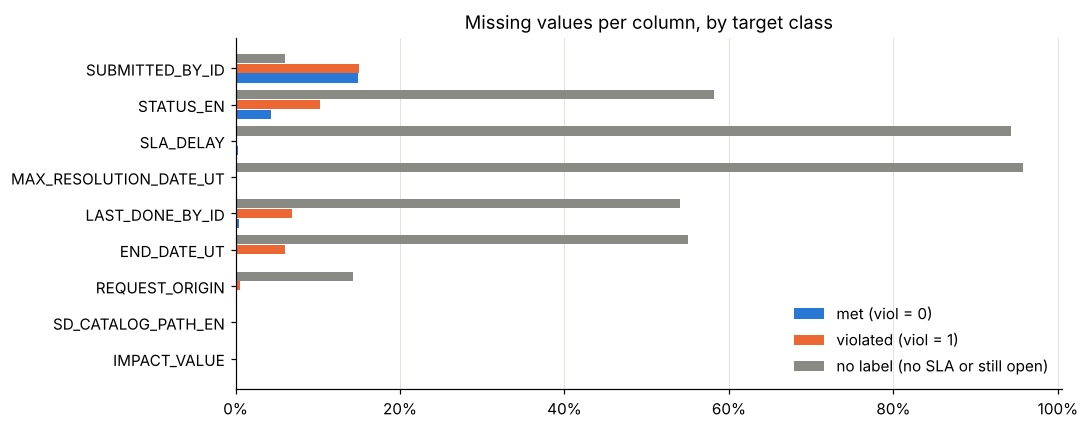

SUBMITTED_BY_ID,submitter known,submitter missing
REQUEST_ORIGIN,,
EV Reach Recovery,0,12
Email,163,8955
Front Office,45243,0
Phone,5883,2
Shopping Cart,110,0
Webservice - CS Platform,12,0
Webservice - ES Platform,1575,0
Webservice - EvO Platform,1511,0
missing,460,249


In [7]:
raw = pd.read_csv(DATA_PATH, sep=";", na_values=["NULL"])
for c in ["SUBMIT_DATE_UT", "MAX_RESOLUTION_DATE_UT", "END_DATE_UT"]:
    raw[c] = pd.to_datetime(raw[c])
RAW_COLS = [c for c in raw.columns if c != "REQUEST_ID"]

miss = df[RAW_COLS].isna()
by_class = pd.DataFrame({
    "missing_% all": miss.mean() * 100,
    "missing_% met (viol=0)": miss[df["viol"] == 0].mean() * 100,
    "missing_% violated (viol=1)": miss[df["viol"] == 1].mean() * 100,
    "missing_% no label": miss[df["viol"].isna()].mean() * 100,
    "viol rate if missing": [df.loc[miss[c], "viol"].mean() for c in RAW_COLS],
    "viol rate if present": [df.loc[~miss[c], "viol"].mean() for c in RAW_COLS],
}).round(2).sort_values("missing_% all", ascending=False)
display(by_class)

show = by_class[by_class["missing_% all"] > 0].iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 4))
yy = np.arange(len(show))
for k, (col, colour, name) in enumerate([("missing_% met (viol=0)", BLUE, "met (viol = 0)"),
                                          ("missing_% violated (viol=1)", ORANGE, "violated (viol = 1)"),
                                          ("missing_% no label", GRAY, "no label (no SLA or still open)")]):
    ax.barh(yy + (k - 1) * 0.27, show[col], height=0.25, color=colour, label=name)
ax.set_yticks(yy, show.index); ax.xaxis.set_major_formatter(PercentFormatter(100))
ax.set_title("Missing values per column, by target class"); ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

# Where do missing submitters come from?
pd.crosstab(df["REQUEST_ORIGIN"].fillna("missing"), df["SUBMITTED_BY_ID"].isna().map({False: "submitter known", True: "submitter missing"}))

**Reading.** Missing values are not random, and the table shows two different situations.
- **Structural missingness, safe to use.** `SUBMITTED_BY_ID` is missing for 14.4% of the tickets, almost the same share in both classes (14.9% vs 15.1%), because it depends on the channel: 98% of e-mails have no submitter, while Front Office tickets always have one. It is kept as an "unknown submitter" level. `SLA_DELAY` and the deadline are missing for tickets without an SLA (Change and Problem), which have no label anyway.
- **Missingness that reveals the target (leak).** `END_DATE_UT`, `LAST_DONE_BY_ID` and `STATUS_EN` are missing much more often for violated tickets (e.g. `LAST_DONE_BY_ID`: 0.4% of met vs 6.9% of violated, and 85% of the tickets where it is missing are violated). These columns are filled in during or after the ticket's life, so they are never used as features; they only appear in the "oracle" upper bound of the baseline notebook.
- `REQUEST_ORIGIN` is missing for 1.1% of the tickets, with a high violation rate (79%) on a small group: kept as its own level.

## 4. Feature statistics and distributions
Numerical columns, both raw and engineered in `prep.py`. `URGENCY_VALUE`, `IMPACT_VALUE` and `SLA_DELAY` are codes (ordinal categories) but are summarised here as numbers too. Skewness 0 = symmetric; kurtosis is the *excess* kurtosis (0 for a normal distribution, large values = heavy tails).

In [8]:
NUM_FEATS = ["URGENCY_VALUE", "IMPACT_VALUE", "SLA_DELAY", "nb_actions", "sla_nominal", "sla_real_hours",
             "open_tickets_at_submit", "open_same_type_at_submit", "open_recent_30d", "arrivals_24h",
             "arrivals_7d", "submitter_prev_tickets", "hour", "dow", "month", "res_hours"]
desc = df[NUM_FEATS].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T
desc["missing_%"] = df[NUM_FEATS].isna().mean() * 100
desc["skewness"] = df[NUM_FEATS].skew()
desc["kurtosis"] = df[NUM_FEATS].kurt()
desc.round(2)

,count,mean,std,min,1%,25%,50%,75%,99%,max,missing_%,skewness,kurtosis
URGENCY_VALUE,64175.0,3.53,1.23,1.0,1.00,3.00,3.00,5.00,5.00,5.00,0.00,-0.05,-1.21
IMPACT_VALUE,64169.0,3.00,0.34,1.0,1.00,3.00,3.00,3.00,4.00,4.00,0.01,-2.49,20.63
SLA_DELAY,60040.0,69.25,51.98,1.0,1.00,40.00,40.00,120.00,135.00,480.00,6.44,0.67,1.76
nb_actions,64175.0,29.06,20.92,1.0,4.00,20.00,25.00,36.00,91.00,865.00,0.00,9.97,273.45
sla_nominal,64175.0,154.03,145.70,1.0,1.00,120.00,120.00,163.00,531.00,5018.28,0.00,5.34,96.47
sla_real_hours,60106.0,200.39,4448.42,1.0,1.00,120.00,122.25,165.21,896.06,1089580.59,6.34,244.36,59842.18
open_tickets_at_submit,64175.0,2408.77,668.68,0.0,272.00,2219.00,2568.00,2902.00,3222.00,3273.00,0.00,-1.32,1.57
open_same_type_at_submit,64175.0,651.16,289.94,0.0,95.00,397.00,726.00,840.00,1750.26,2038.00,0.00,0.82,2.48
open_recent_30d,64175.0,610.39,105.36,0.0,272.00,562.00,604.00,644.00,1007.00,1050.00,0.00,0.56,7.79
arrivals_24h,64175.0,119.30,52.20,0.0,6.00,93.00,126.00,145.00,272.00,575.00,0.00,1.54,12.63


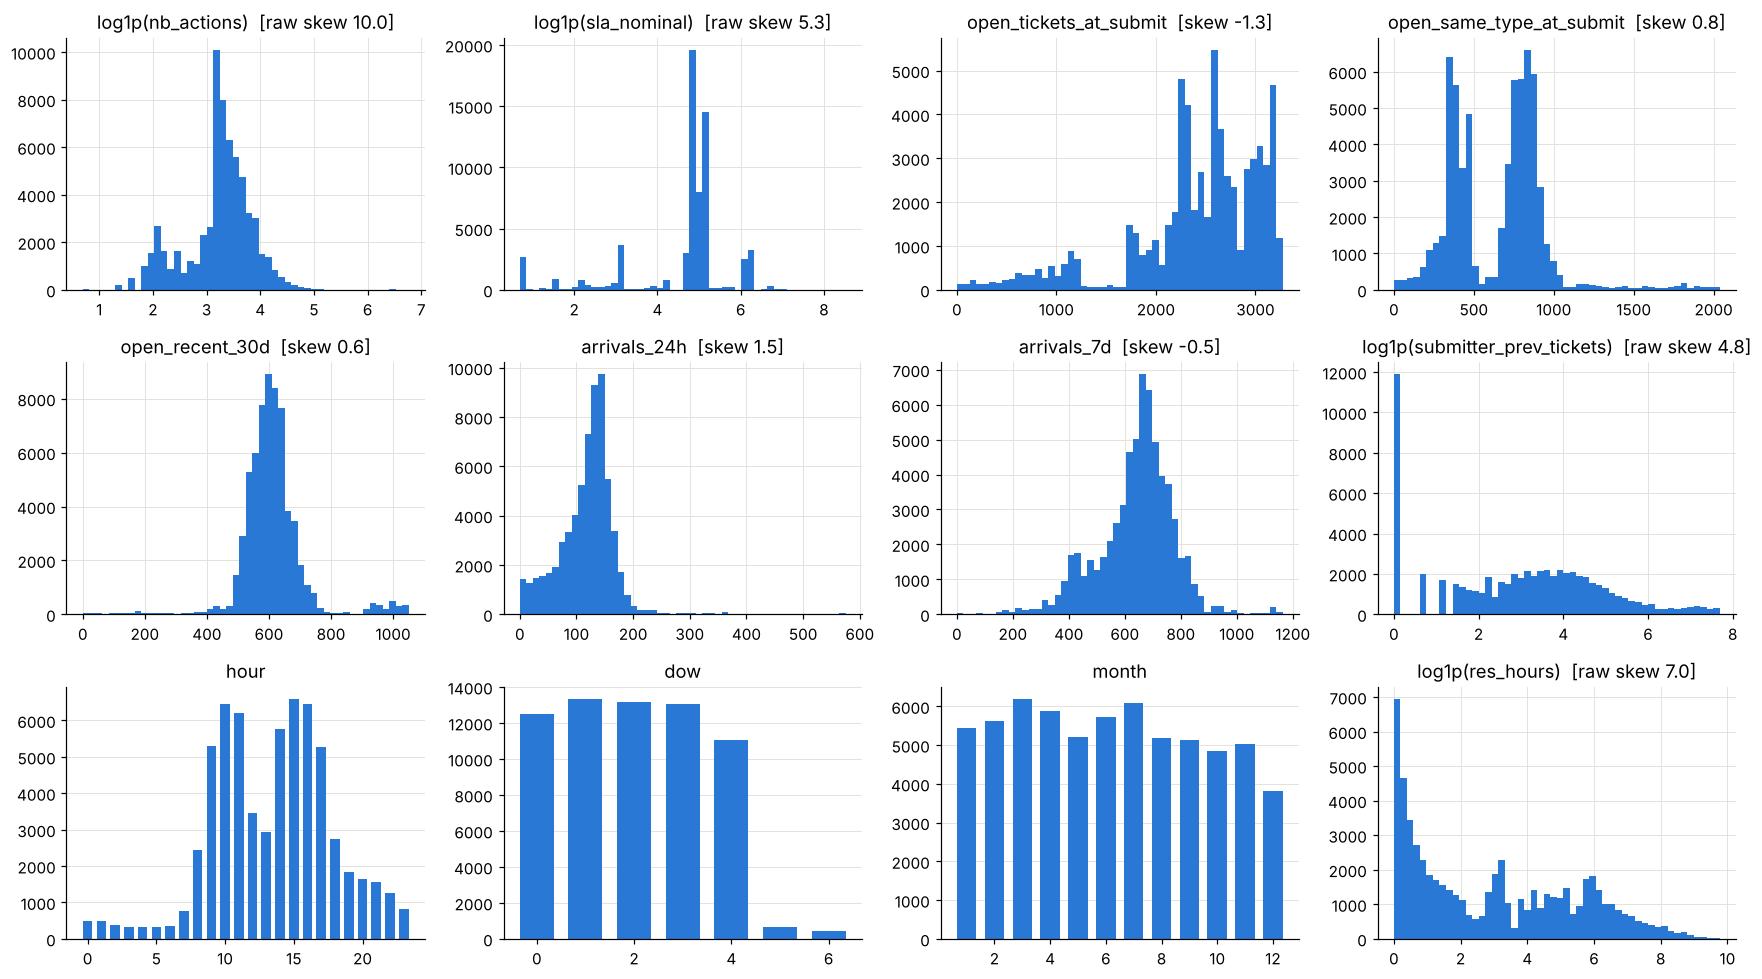

In [9]:
# Histograms; features with skewness > 2 are also shown on a log1p scale
HIST = ["nb_actions", "sla_nominal", "open_tickets_at_submit", "open_same_type_at_submit", "open_recent_30d",
        "arrivals_24h", "arrivals_7d", "submitter_prev_tickets", "hour", "dow", "month", "res_hours"]
fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for ax, c in zip(axes.flat, HIST):
    x = df[c].dropna()
    if c in ("hour", "dow", "month"):
        vc = x.value_counts().sort_index()
        ax.bar(vc.index, vc.values, color=BLUE, width=0.7); ax.grid(axis="x", visible=False)
        ax.set_title(c)
    elif x.skew() > 2:
        ax.hist(np.log1p(x.clip(lower=0)), bins=50, color=BLUE)
        ax.set_title(f"log1p({c})  [raw skew {x.skew():.1f}]")
    else:
        ax.hist(x, bins=50, color=BLUE)
        ax.set_title(f"{c}  [skew {x.skew():.1f}]")
plt.tight_layout(); plt.show()

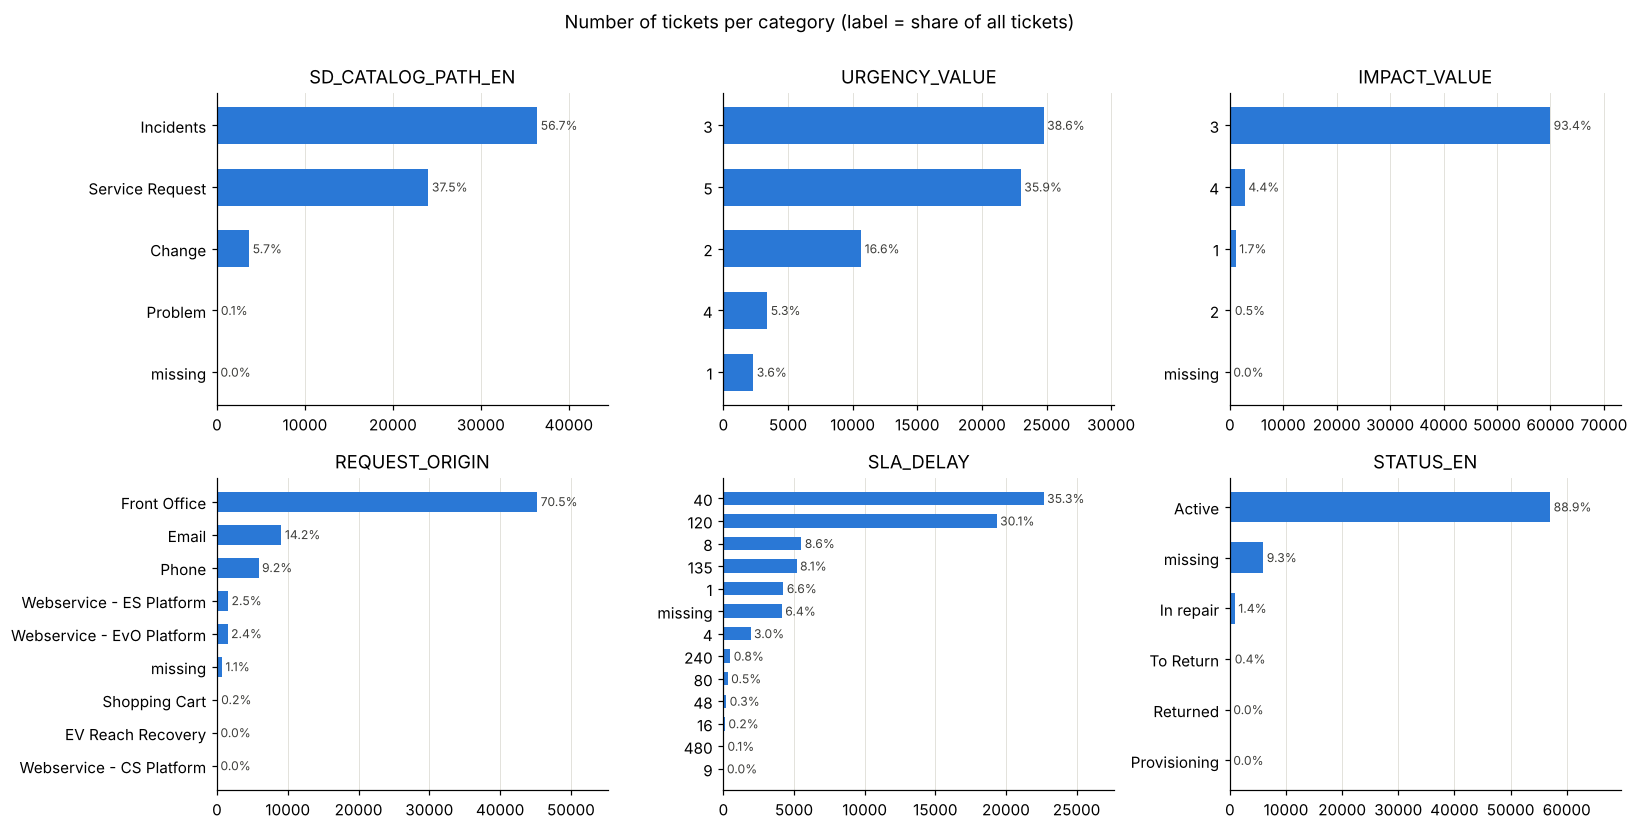

In [10]:
CAT_COLS = ["SD_CATALOG_PATH_EN", "URGENCY_VALUE", "IMPACT_VALUE", "REQUEST_ORIGIN", "SLA_DELAY", "STATUS_EN"]

def as_label(s):
    """Categorical column as readable strings (numeric codes without '.0'), missing as 'missing'."""
    if pd.api.types.is_numeric_dtype(s):
        s = s.astype("Int64")
    return s.astype("string").fillna("missing")

fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
for ax, c in zip(axes.flat, CAT_COLS):
    vc = as_label(df[c]).value_counts().iloc[::-1]          # largest on top
    ax.barh(vc.index, vc.values, color=BLUE, height=0.6)
    for y, v in enumerate(vc.values):
        ax.text(v, y, f" {v / len(df):.1%}", va="center", fontsize=8, color=INK)
    ax.set_title(c); ax.grid(axis="y", visible=False)
    ax.set_xlim(0, vc.max() * 1.22)
fig.suptitle("Number of tickets per category (label = share of all tickets)", y=1.0)
plt.tight_layout(); plt.show()

**Reading.**
- **Heavy tails:** `nb_actions` (skewness 10, kurtosis 273, up to 865 actions), `sla_nominal` (5.3), `submitter_prev_tickets` (4.8) and `res_hours` (7.0). `sla_real_hours` has an absurd kurtosis (≈ 60,000) because of a single ticket whose deadline is 124 years after submission (section 7): one more reason to use the nominal deadline. On the log scale these features become close to symmetric.
- **Coded variables:** urgency is spread over 1–5; `IMPACT_VALUE` is 3 for 93% of the tickets (kurtosis 21), so it carries little information.
- **Load features** are roughly symmetric, except `open_tickets_at_submit`, which is skewed to the left: the cumulative counter starts from zero in September 2022 and grows during the first months (warm-up). `open_same_type_at_submit` is bimodal because Incidents and Service Requests have different backlogs.
- **Calendar:** two peaks per day (morning and afternoon, with a lunch dip), almost no tickets at the weekend, and a slightly lower volume in December.
- Tree models do not need transformed inputs; linear models (logistic regression, Ridge) are given log-transformed and standardised features.

## 5. Outliers
Tukey's IQR rule: a value is an outlier if it is below Q1 − 1.5·IQR or above Q3 + 1.5·IQR, where IQR = Q3 − Q1. For very skewed features the rule is also applied on the log scale, where it is more meaningful.

,Q1,Q3,IQR,lower_fence,upper_fence,n_outliers,outliers_pct,outliers_pct_log_scale,viol_rate_outliers,viol_rate_others
feature,,,,,,,,,,
nb_actions,20.00,36.00,16.00,-4.00,60.00,3163,4.93,10.56,0.65,0.24
sla_nominal,120.00,163.00,43.00,55.50,227.50,17961,27.99,29.34,0.30,0.24
open_tickets_at_submit,2219.00,2902.00,683.00,1194.50,3926.50,6004,9.36,10.35,0.33,0.25
open_same_type_at_submit,397.00,840.00,443.00,-267.50,1504.50,1072,1.67,1.43,0.00,0.26
open_recent_30d,562.00,644.00,82.00,439.00,767.00,4071,6.34,6.49,0.30,0.26
arrivals_24h,93.00,145.00,52.00,15.00,223.00,2865,4.46,10.35,0.31,0.26
arrivals_7d,574.00,722.00,148.00,352.00,944.00,2380,3.71,6.87,0.35,0.26
submitter_prev_tickets,3.00,74.00,71.00,-103.50,180.50,7214,11.24,0.00,0.22,0.26
res_hours,0.82,158.05,157.23,-235.02,393.89,8990,14.76,0.00,0.90,0.14


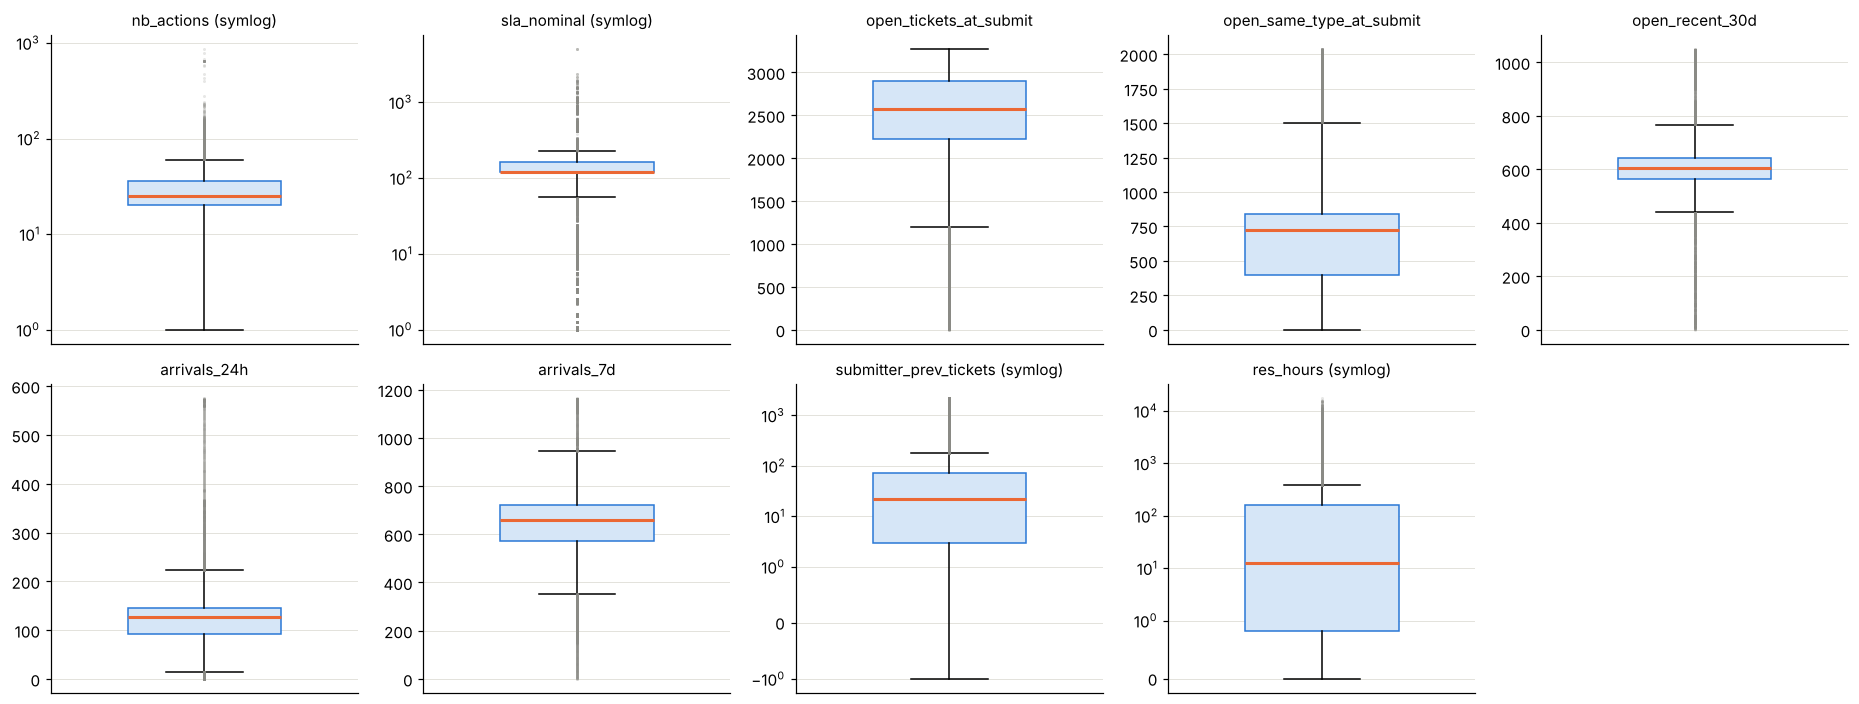

In [11]:
OUT_FEATS = ["nb_actions", "sla_nominal", "open_tickets_at_submit", "open_same_type_at_submit", "open_recent_30d",
             "arrivals_24h", "arrivals_7d", "submitter_prev_tickets", "res_hours"]

def iqr_outliers(x):
    q1, q3 = x.quantile([0.25, 0.75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return q1, q3, iqr, lo, hi, (x < lo) | (x > hi)

rows = []
for c in OUT_FEATS:
    x = df[c].dropna()
    q1, q3, iqr, lo, hi, out = iqr_outliers(x)
    *_, out_log = iqr_outliers(np.log1p(x.clip(lower=0)))
    rows.append(dict(feature=c, Q1=q1, Q3=q3, IQR=iqr, lower_fence=lo, upper_fence=hi, n_outliers=out.sum(),
                     outliers_pct=100 * out.mean(), outliers_pct_log_scale=100 * out_log.mean(),
                     viol_rate_outliers=df.loc[out[out].index, "viol"].mean(),
                     viol_rate_others=df.loc[out[~out].index, "viol"].mean()))
display(pd.DataFrame(rows).set_index("feature").round(2))

fig, axes = plt.subplots(2, 5, figsize=(17, 6.5))
for ax, c in zip(axes.flat, OUT_FEATS):
    x = df[c].dropna()
    ax.boxplot(x, vert=True, widths=0.5, patch_artist=True, showfliers=True,
               boxprops=dict(facecolor="#d6e6f7", edgecolor=BLUE), medianprops=dict(color=ORANGE, lw=2),
               flierprops=dict(marker="o", markersize=2, alpha=0.2, markerfacecolor=GRAY, markeredgecolor="none"))
    ax.set_title(c, fontsize=10); ax.set_xticks([])
    if x.skew() > 2:
        ax.set_yscale("symlog", linthresh=1); ax.set_title(c + " (symlog)", fontsize=10)
axes.flat[-1].axis("off")
plt.tight_layout(); plt.show()

**Reading.** The IQR rule flags many points, but almost none of them are errors.
- `res_hours`: 14.8% are outliers on the raw scale and **0%** on the log scale. These are the genuine long tail of slow tickets, not anomalies; removing them would bias the regression. The same holds for `submitter_prev_tickets` (11.2% → 0%).
- `sla_nominal`: 28% flagged, because most tickets share a few standard SLA lengths (Q1 and median are both 120 hours) and the IQR is very narrow. The rule does not make sense for a variable with a few discrete values.
- `open_tickets_at_submit`: the 9.4% low outliers are the warm-up months at the start of the data.
- `nb_actions`: the 4.9% of tickets with more than 60 actions are violated 65% of the time (24% for the others), but this is an "after the fact" feature.
- **Decision:** no rows are dropped as statistical outliers. Heavy tails are handled with log transforms and with tree models, which are insensitive to monotone transformations; real errors are handled by the rules of section 7.

## 6. Correlation between features
Numerical features (and the two targets): Spearman rank correlation, robust to skewness and outliers. Categorical features: Cramér's V (0 = independent, 1 = one determines the other).

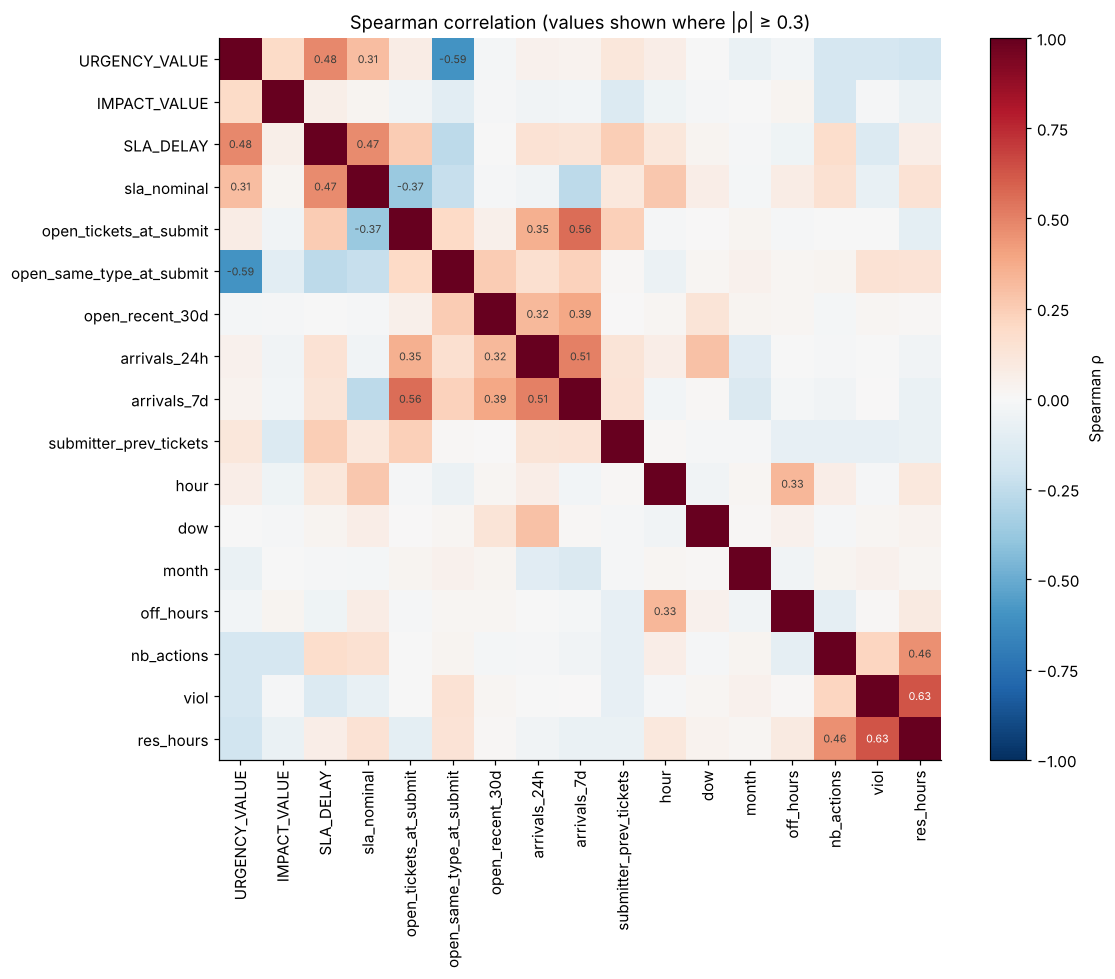

Strongest pairs:
viol                    res_hours                   0.629
URGENCY_VALUE           open_same_type_at_submit   -0.594
open_tickets_at_submit  arrivals_7d                 0.557
arrivals_24h            arrivals_7d                 0.506
URGENCY_VALUE           SLA_DELAY                   0.484
SLA_DELAY               sla_nominal                 0.470
nb_actions              res_hours                   0.457
open_recent_30d         arrivals_7d                 0.389
sla_nominal             open_tickets_at_submit     -0.372
open_tickets_at_submit  arrivals_24h                0.354

Correlation with the targets (Spearman):
                           viol  res_hours
URGENCY_VALUE            -0.164     -0.192
open_tickets_at_submit   -0.001     -0.101
IMPACT_VALUE             -0.012     -0.069
arrivals_7d               0.007     -0.067
submitter_prev_tickets   -0.078     -0.066
arrivals_24h             -0.002     -0.037
open_recent_30d           0.022      0.012
month            

In [12]:
CORR = ["URGENCY_VALUE", "IMPACT_VALUE", "SLA_DELAY", "sla_nominal", "open_tickets_at_submit",
        "open_same_type_at_submit", "open_recent_30d", "arrivals_24h", "arrivals_7d", "submitter_prev_tickets",
        "hour", "dow", "month", "off_hours", "nb_actions", "viol", "res_hours"]
rho = df[CORR].corr(method="spearman")
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(rho.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(CORR)), CORR, rotation=90); ax.set_yticks(range(len(CORR)), CORR); ax.grid(False)
for i in range(len(CORR)):
    for j in range(len(CORR)):
        v = rho.values[i, j]
        if i != j and abs(v) >= 0.3:
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if abs(v) > 0.6 else INK)
fig.colorbar(im, ax=ax, fraction=0.04, label="Spearman ρ")
ax.set_title("Spearman correlation (values shown where |ρ| ≥ 0.3)")
plt.tight_layout(); plt.show()

pairs = rho.where(np.triu(np.ones(rho.shape, dtype=bool), 1)).stack().rename("rho")
print("Strongest pairs:")
print(pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(10).round(3).to_string())
print("\nCorrelation with the targets (Spearman):")
print(rho[["viol", "res_hours"]].drop(["viol", "res_hours"]).round(3).sort_values("res_hours").to_string())

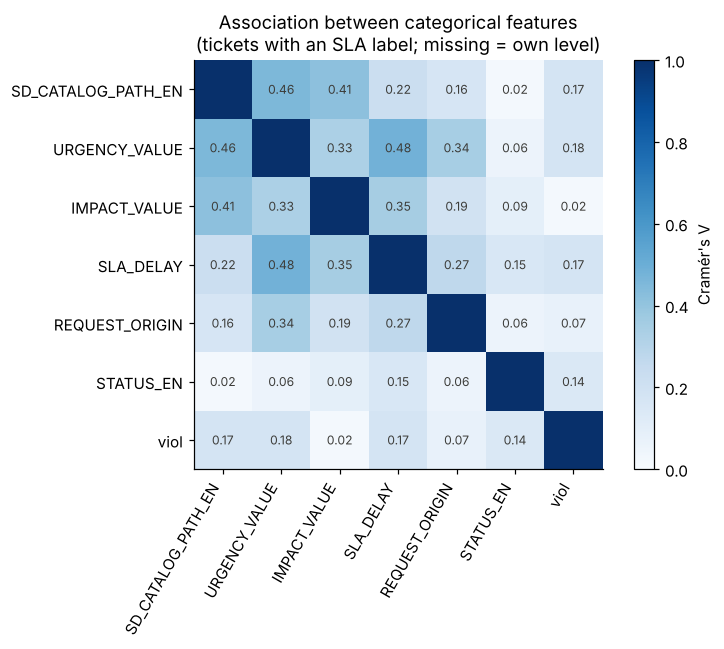

In [13]:
def cramers_v(a, b):
    """Bias-corrected Cramér's V between two categorical series (Bergsma, 2013)."""
    t = pd.crosstab(a, b)
    chi2 = stats.chi2_contingency(t, correction=False)[0]
    n = t.values.sum(); r, k = t.shape
    phi2 = max(0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    r2, k2 = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2 / max(min(k2 - 1, r2 - 1), 1e-12))

CATS = ["SD_CATALOG_PATH_EN", "URGENCY_VALUE", "IMPACT_VALUE", "SLA_DELAY", "REQUEST_ORIGIN", "STATUS_EN", "viol"]
lab_c = df[df["viol"].notna()]
V = pd.DataFrame(index=CATS, columns=CATS, dtype=float)
for a in CATS:
    for b in CATS:
        V.loc[a, b] = 1.0 if a == b else cramers_v(as_label(lab_c[a]), as_label(lab_c[b]))
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(V.values, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(CATS)), CATS, rotation=60, ha="right"); ax.set_yticks(range(len(CATS)), CATS); ax.grid(False)
for i in range(len(CATS)):
    for j in range(len(CATS)):
        if i != j:
            ax.text(j, i, f"{V.values[i, j]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if V.values[i, j] > 0.6 else INK)
fig.colorbar(im, ax=ax, fraction=0.045, label="Cramér's V")
ax.set_title("Association between categorical features\n(tickets with an SLA label; missing = own level)")
plt.tight_layout(); plt.show()

**Reading.**
- **Targets:** the two targets are strongly related (ρ = 0.63 between `viol` and `res_hours`): slow tickets are the ones that violate the SLA (see 8e).
- **Redundant features:** the load counters are correlated with each other (`open_tickets_at_submit`–`arrivals_7d` 0.56, `arrivals_24h`–`arrivals_7d` 0.51), and `SLA_DELAY` is linked to urgency (0.48) and to `sla_nominal` (0.47). No pair is close to 1, so no feature has to be dropped; for linear models the correlated load counters can be reduced.
- `URGENCY_VALUE`–`open_same_type_at_submit` (−0.59) is a ticket-type effect: urgency codes and backlog levels differ between Incidents and Service Requests.
- **Single features and the target are weakly correlated:** the strongest at submission are urgency (−0.16), `open_same_type_at_submit` (0.15) and `SLA_DELAY` (−0.14); `nb_actions` (0.21) is post-hoc. No single variable explains the violation, which supports non-linear models that combine features.
- **Categorical features:** moderate associations (type–urgency 0.46, urgency–`SLA_DELAY` 0.48, type–impact 0.41), none redundant. The association with `viol` is highest for urgency (0.18), type and `SLA_DELAY` (0.17); `IMPACT_VALUE` is practically unrelated (0.02).

## 7. Sanity checks: errors per feature and their distribution
Every column is checked against what it should contain. Each rule flags tickets whose values are impossible or suspicious; then we look at how the flagged tickets are spread across the target classes and the ticket types.

In [14]:
end_raw = df[["REQUEST_ID"]].merge(raw[["REQUEST_ID", "END_DATE_UT"]], on="REQUEST_ID", how="left")["END_DATE_UT"].values
closed_mask = df["END_DATE_UT"].notna()
age_days = (df.attrs["extract_date"] - df["SUBMIT_DATE_UT"]).dt.days
RULES = {
    # rule name: (feature, boolean mask)
    "duplicated REQUEST_ID": ("REQUEST_ID", df["REQUEST_ID"].duplicated(keep=False)),
    "closing date before submission": ("END_DATE_UT", pd.Series(end_raw < df["SUBMIT_DATE_UT"].values, index=df.index)),
    "deadline before submission": ("MAX_RESOLUTION_DATE_UT", df["MAX_RESOLUTION_DATE_UT"] < df["SUBMIT_DATE_UT"]),
    "deadline but no SLA_DELAY": ("SLA_DELAY", df["MAX_RESOLUTION_DATE_UT"].notna() & df["SLA_DELAY"].isna()),
    "SLA_DELAY but no deadline": ("MAX_RESOLUTION_DATE_UT", df["MAX_RESOLUTION_DATE_UT"].isna() & df["SLA_DELAY"].notna()),
    "deadline more than 1 year after submission": ("MAX_RESOLUTION_DATE_UT", df["sla_real_hours"] > 24 * 365),
    "deadline extended after submission": ("MAX_RESOLUTION_DATE_UT", df["deadline_extended"] == 1),
    "URGENCY_VALUE outside 1-5": ("URGENCY_VALUE", ~df["URGENCY_VALUE"].isin(range(1, 6))),
    "IMPACT_VALUE outside 1-4": ("IMPACT_VALUE", df["IMPACT_VALUE"].notna() & ~df["IMPACT_VALUE"].isin(range(1, 5))),
    "nb_actions <= 0": ("nb_actions", df["nb_actions"] <= 0),
    "closed in under 1 minute": ("END_DATE_UT", df["res_hours"] < 1 / 60),
    "resolution longer than 1 year": ("END_DATE_UT", df["res_hours"] > 24 * 365),
    "open for more than 6 months at extraction": ("END_DATE_UT", (df["never_closed"] == 1) & (age_days > 180)),
    "closed but LAST_DONE_BY_ID missing": ("LAST_DONE_BY_ID", closed_mask & df["LAST_DONE_BY_ID"].isna()),
    "open but LAST_DONE_BY_ID filled": ("LAST_DONE_BY_ID", ~closed_mask & df["LAST_DONE_BY_ID"].notna()),
    "STATUS_EN missing": ("STATUS_EN", df["STATUS_EN"].isna()),
    "Front Office ticket without submitter": ("SUBMITTED_BY_ID", (df["REQUEST_ORIGIN"] == "Front Office") & df["SUBMITTED_BY_ID"].isna()),
}
flags = pd.DataFrame({k: m.astype(bool).values for k, (_, m) in RULES.items()}, index=df.index)
cls = df["viol"].map({0: "met (0)", 1: "violated (1)"}).fillna("no label")

err = pd.DataFrame({
    "feature": [f for f, _ in RULES.values()],
    "n": flags.sum(),
    "% of all": 100 * flags.mean(),
    "% of met (0)": 100 * flags[cls == "met (0)"].mean(),
    "% of violated (1)": 100 * flags[cls == "violated (1)"].mean(),
    "% of no label": 100 * flags[cls == "no label"].mean(),
    "viol rate if flagged": [df.loc[flags[k], "viol"].mean() if flags[k].any() else np.nan for k in RULES],
}).round(2)
err

,feature,n,% of all,% of met (0),% of violated (1),% of no label,viol rate if flagged
duplicated REQUEST_ID,REQUEST_ID,0,0.00,0.00,0.00,0.00,NaN
closing date before submission,END_DATE_UT,66,0.10,0.00,0.43,0.00,1.00
deadline before submission,MAX_RESOLUTION_DATE_UT,0,0.00,0.00,0.00,0.00,NaN
deadline but no SLA_DELAY,SLA_DELAY,131,0.20,0.25,0.11,0.05,0.13
SLA_DELAY but no deadline,MAX_RESOLUTION_DATE_UT,65,0.10,0.00,0.00,1.53,NaN
deadline more than 1 year after submission,MAX_RESOLUTION_DATE_UT,1,0.00,0.00,0.00,0.00,0.00
deadline extended after submission,MAX_RESOLUTION_DATE_UT,5761,8.98,6.84,17.50,0.28,0.47
URGENCY_VALUE outside 1-5,URGENCY_VALUE,0,0.00,0.00,0.00,0.00,NaN
IMPACT_VALUE outside 1-4,IMPACT_VALUE,0,0.00,0.00,0.00,0.00,NaN
nb_actions <= 0,nb_actions,0,0.00,0.00,0.00,0.00,NaN


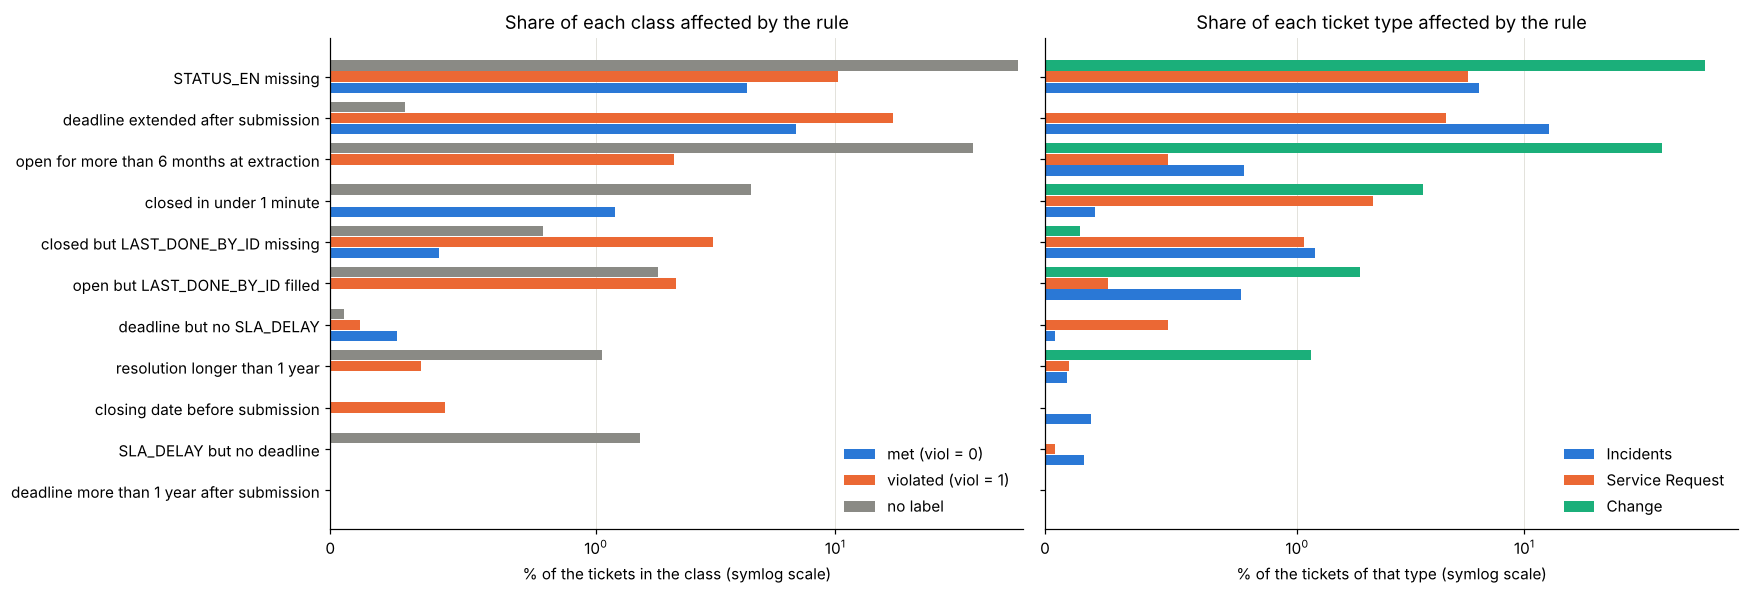

tickets with at least one hard error (excluding missing status and extended deadlines): 3,711 (5.8%)
errors per ticket  0 errors  1 error  2+ errors
target class                                   
met (0)               0.982    0.018      0.000
no label              0.542    0.445      0.013
violated (1)          0.939    0.044      0.017


In [15]:
# Distribution of the flagged tickets across target classes and ticket types (rules with at least one hit)
hit = err[err["n"] > 0].sort_values("n").index
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), sharey=True)
yy = np.arange(len(hit))
for k, (col, colour, name) in enumerate([("% of met (0)", BLUE, "met (viol = 0)"),
                                          ("% of violated (1)", ORANGE, "violated (viol = 1)"),
                                          ("% of no label", GRAY, "no label")]):
    axes[0].barh(yy + (k - 1) * 0.27, err.loc[hit, col], height=0.25, color=colour, label=name)
axes[0].set_yticks(yy, hit); axes[0].set_xscale("symlog", linthresh=1)
axes[0].set_xlabel("% of the tickets in the class (symlog scale)"); axes[0].grid(axis="y", visible=False)
axes[0].set_title("Share of each class affected by the rule"); axes[0].legend(frameon=False, loc="lower right")

by_type = flags.groupby(df["SD_CATALOG_PATH_EN"]).mean().T.loc[hit] * 100
for k, (cat, colour) in enumerate([("Incidents", BLUE), ("Service Request", ORANGE), ("Change", AQUA)]):
    axes[1].barh(yy + (k - 1) * 0.27, by_type[cat], height=0.25, color=colour, label=cat)
axes[1].set_xscale("symlog", linthresh=1); axes[1].set_xlabel("% of the tickets of that type (symlog scale)")
axes[1].set_title("Share of each ticket type affected by the rule"); axes[1].grid(axis="y", visible=False)
axes[1].legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

n_err = flags.drop(columns=["STATUS_EN missing", "deadline extended after submission"]).sum(axis=1)
print("tickets with at least one hard error (excluding missing status and extended deadlines):",
      f"{(n_err > 0).sum():,} ({(n_err > 0).mean():.1%})")
tab = pd.crosstab(cls.rename("target class"), n_err.clip(upper=2).map({0: "0 errors", 1: "1 error", 2: "2+ errors"}).rename("errors per ticket"), normalize="index")
print(tab.round(3))

**Reading.**
- **Clean columns:** no duplicated IDs, no urgency or impact codes outside their range, no zero or negative `nb_actions`, no deadline before the submission, and every Front Office ticket has a submitter.
- **Date errors:** 66 closing dates are before the submission. `prep.py` treats them as missing, which makes these tickets "never closed and overdue", so all 66 end up labelled as violated: their label is uncertain. One deadline is 124 years after the submission.
- **SLA inconsistencies:** 131 tickets have a deadline but no `SLA_DELAY`, and 65 the opposite. 9% of the deadlines are extended after submission, and this is much more frequent among violated tickets (17.5%) than among met ones (6.8%), and among Incidents (about 13%).
- **Suspicious durations:** 721 tickets (1.1%) are closed in less than a minute and are never violated (duplicates or automatic closures); 98 take more than a year; 1,921 are still open after more than 6 months, mostly Changes and tickets without a label.
- **`LAST_DONE_BY_ID` inconsistent with the status:** 697 closed tickets have no last actor, and 412 open tickets have one (every one of them with a label is violated).
- **Distribution across classes:** 5.8% of the tickets have at least one hard error. They are rare among met tickets (1.8%), more frequent among violated ones (6.1%), and concentrated among unlabelled tickets (46%), which are not used for the classification. Errors therefore affect the violated class more than the met one, which is worth reporting with the metrics (the test is also evaluated without never-closed tickets in notebook 02).

## 8. Additional analysis

### 8a. Volume over time

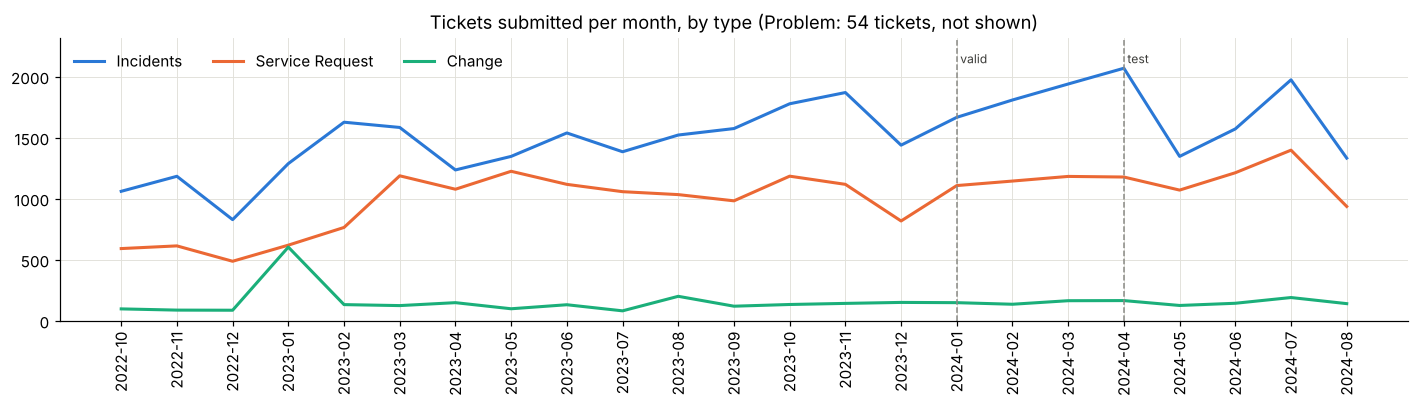

In [16]:
# Monthly volume by ticket type (the first and last months are partial and are dropped)
m = df.groupby([df["SUBMIT_DATE_UT"].dt.to_period("M"), "SD_CATALOG_PATH_EN"]).size().unstack(fill_value=0)
m = m.iloc[1:-1]
fig, ax = plt.subplots(figsize=(13, 3.8))
for cat, col in [("Incidents", BLUE), ("Service Request", ORANGE), ("Change", AQUA)]:
    ax.plot(m.index.astype(str), m[cat], color=col, lw=2, label=cat)
ax.axvline(str(TEST_START.to_period("M")), color=GRAY, lw=1, ls="--")
ax.axvline(str(VALID_START.to_period("M")), color=GRAY, lw=1, ls="--")
ax.text(str(VALID_START.to_period("M")), m.values.max() * 1.02, " valid", fontsize=8, color=INK)
ax.text(str(TEST_START.to_period("M")), m.values.max() * 1.02, " test", fontsize=8, color=INK)
ax.set_title("Tickets submitted per month, by type (Problem: 54 tickets, not shown)")
ax.set_ylim(0, m.values.max() * 1.12); ax.tick_params(axis="x", rotation=90)
ax.legend(frameon=False, ncol=3, loc="upper left")
plt.tight_layout(); plt.show()

**Reading.** The volume of Incidents roughly doubles between the end of 2022 and spring 2024, with a dip in December 2023. Change shows a one-off spike in January 2023. Because volume and mix change over time, a random train/test split would be too optimistic: we split by date.

### 8b. Targets by subgroup
Violation rate and resolution time across the main categories. The dashed line is the overall violation rate.

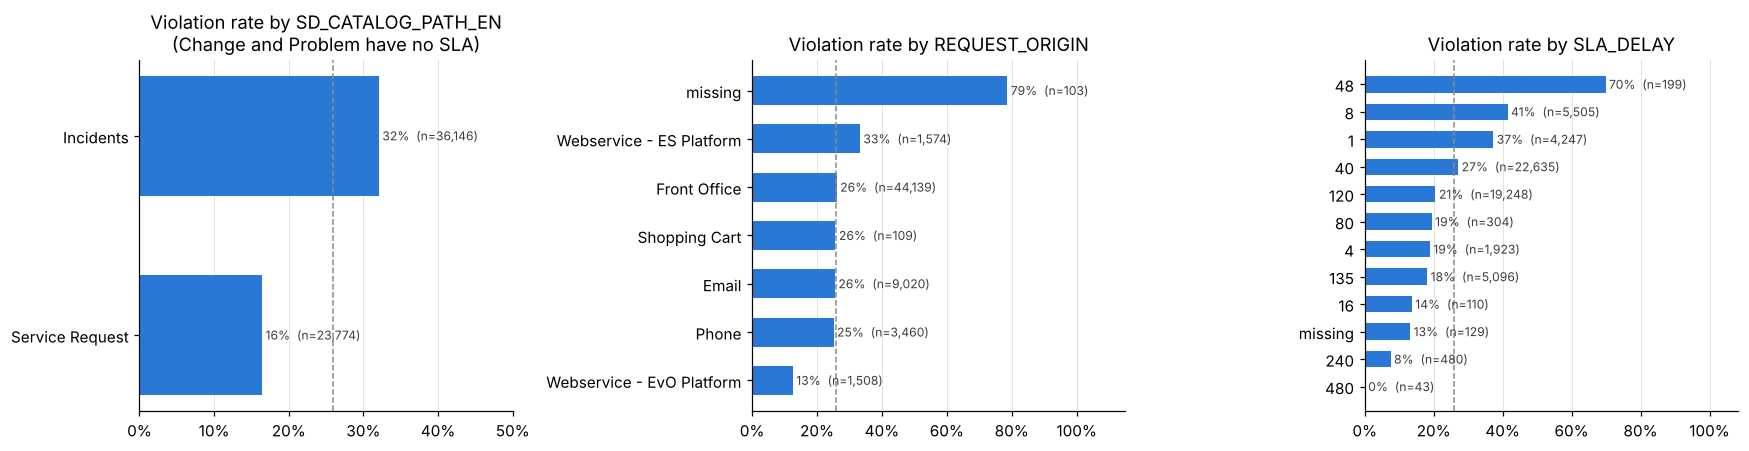

In [17]:
lab = df[df["viol"].notna()]
overall = lab["viol"].mean()
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, c in zip(axes, ["SD_CATALOG_PATH_EN", "REQUEST_ORIGIN", "SLA_DELAY"]):
    g = lab.groupby(as_label(lab[c]))["viol"].agg(["mean", "size"])
    g = g[g["size"] >= 30].sort_values("mean")              # groups with fewer than 30 tickets are hidden
    ax.barh(g.index, g["mean"], color=BLUE, height=0.6)
    for y, (r, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(r, y, f" {r:.0%}  (n={n:,})", va="center", fontsize=8, color=INK)
    ax.axvline(overall, color=GRAY, lw=1, ls="--")
    ax.set_xlim(0, min(g["mean"].max() * 1.55, 1.15)); ax.grid(axis="y", visible=False)
    ax.xaxis.set_major_formatter(PercentFormatter(1)); ax.set_xticks([t for t in ax.get_xticks() if t <= 1])
    ax.set_title(f"Violation rate by {c}")
axes[0].set_title("Violation rate by SD_CATALOG_PATH_EN\n(Change and Problem have no SLA)")
plt.tight_layout(); plt.show()

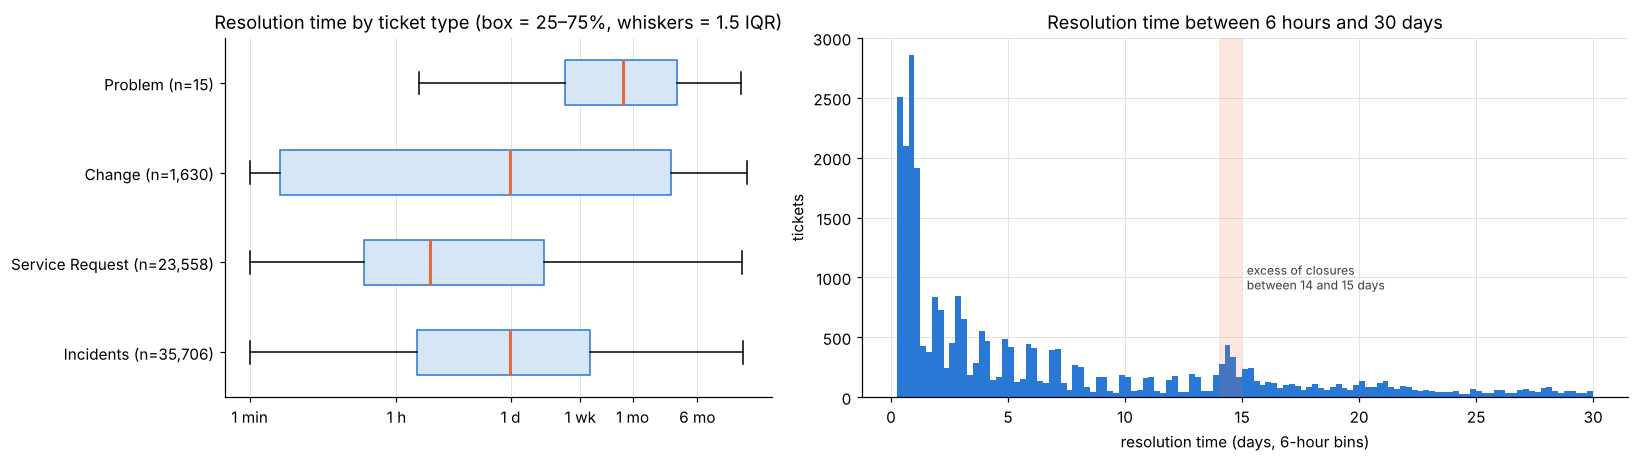

closed after 13-14 / 14-15 / 15-16 days: [np.int64(450), np.int64(1222), np.int64(717)]


,count,mean,std,min,25%,50%,75%,90%,max
SD_CATALOG_PATH_EN,,,,,,,,,
Incidents,35706.0,274.0,767.8,0.0,1.8,23.5,219.1,660.8,15653.0
Service Request,23558.0,196.1,728.5,0.0,0.4,2.6,61.3,432.7,15171.1
Change,1630.0,1426.4,2532.4,0.0,0.0,23.4,2118.9,4898.4,17478.6
Problem,15.0,2463.8,4356.9,1.9,110.6,553.3,2501.5,7606.3,14734.6


In [18]:
closed = df[df["res_hours"].notna()]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.3), gridspec_kw={"width_ratios": [1, 1.4]})

order = ["Incidents", "Service Request", "Change", "Problem"]
data = [np.log10(closed.loc[closed["SD_CATALOG_PATH_EN"] == c, "res_hours"].clip(lower=1 / 60)) for c in order]
bp = axes[0].boxplot(data, vert=False, widths=0.5, showfliers=False, patch_artist=True,
                     medianprops=dict(color=ORANGE, lw=2))
for b in bp["boxes"]:
    b.set(facecolor="#d6e6f7", edgecolor=BLUE)
axes[0].set_yticks(range(1, 5), [f"{c} (n={len(x):,})" for c, x in zip(order, data)])
ticks = {"1 min": 1 / 60, "1 h": 1, "1 d": 24, "1 wk": 168, "1 mo": 720, "6 mo": 4380}
axes[0].set_xticks(np.log10(list(ticks.values())), list(ticks.keys()))
axes[0].set_title("Resolution time by ticket type (box = 25–75%, whiskers = 1.5 IQR)")
axes[0].grid(axis="y", visible=False)

# Zoom on 6 hours - 30 days: daily waves (closures happen in working hours) and a spike at 14-15 days
days = closed["res_hours"] / 24
axes[1].hist(days[(days >= 0.25) & (days <= 30)], bins=np.arange(0.25, 30.01, 0.25), color=BLUE)
axes[1].axvspan(14, 15, color=ORANGE, alpha=0.15, lw=0)
axes[1].text(15.2, axes[1].get_ylim()[1] * 0.3, "excess of closures\nbetween 14 and 15 days", color=INK, fontsize=8)
axes[1].set_xlabel("resolution time (days, 6-hour bins)"); axes[1].set_ylabel("tickets")
axes[1].set_title("Resolution time between 6 hours and 30 days")
plt.tight_layout(); plt.show()

n_day = {k: ((days >= k) & (days < k + 1)).sum() for k in [13, 14, 15]}
print("closed after 13-14 / 14-15 / 15-16 days:", list(n_day.values()))
closed.groupby("SD_CATALOG_PATH_EN")["res_hours"].describe(percentiles=[0.25, 0.5, 0.75, 0.9]).round(1).loc[order]

**Reading.** Only Incidents and Service Requests have an SLA. Incidents are violated twice as often (32% vs 16%). Among channels, *Webservice - ES Platform* is above average (33%) and *EvO Platform* well below (13%); the 103 tickets without an origin are violated 79% of the time, a small but odd group to check with EasyVista. Short deadlines are violated much more often: 41% for 8 hours and 37% for 1 hour, against 8% for 240 hours and none for 480.

Resolution times span six orders of magnitude: 26% of the closed tickets are resolved within an hour and 58% within a day, while the 99th percentile is around half a year. Service Requests are fast (median 2.6 h), Incidents and Changes slower (median about 23 h), and Changes have the widest spread. This long tail is why the regression target is `log1p(hours)`. The histogram shows daily waves (closures happen in working hours) and an excess of closures between 14 and 15 days (1,222 tickets against 450 and 717 in the days before and after, mostly Incidents): probably an automatic closure after two weeks, to confirm with EasyVista.

### 8c. When tickets arrive
Hour and day of the week are in Paris local time (as built in `prep.py`).

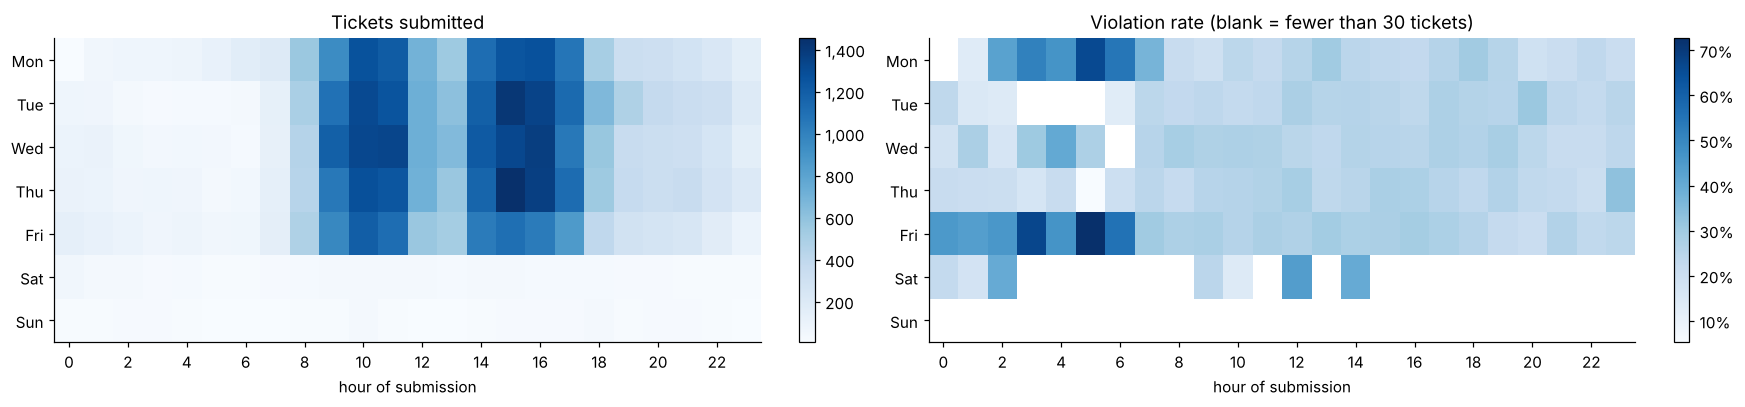

n  viol_rate  median_res_hours
condition                                        value                                    
weekend                                          no     63105      0.259            11.518
                                                 yes     1070      0.247            43.385
off hours (before 8, after 18, weekend, holiday) no     49951      0.256             6.280
                                                 yes    14224      0.268            20.404
French public holiday                            no     63456      0.259            12.539
                                                 yes      719      0.244            23.932

In [19]:
DOW = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
vol = df.pivot_table(index="dow", columns="hour", values="REQUEST_ID", aggfunc="size", fill_value=0)
vr = lab.pivot_table(index="dow", columns="hour", values="viol", aggfunc="mean")
vr_n = lab.pivot_table(index="dow", columns="hour", values="viol", aggfunc="size")
vr = vr.where(vr_n >= 30)                                   # hide cells with fewer than 30 tickets

fig, axes = plt.subplots(1, 2, figsize=(16, 3.8))
for ax, mat, title, fmt in [(axes[0], vol, "Tickets submitted", "{:,.0f}"),
                            (axes[1], vr, "Violation rate (blank = fewer than 30 tickets)", "{:.0%}")]:
    im = ax.imshow(mat.values, aspect="auto", cmap="Blues")
    ax.set_yticks(range(7), DOW); ax.set_xticks(range(0, 24, 2), range(0, 24, 2))
    ax.set_xlabel("hour of submission"); ax.set_title(title); ax.grid(False)
    cb = fig.colorbar(im, ax=ax, fraction=0.025)
    cb.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _, f=fmt: f.format(v)))
plt.tight_layout(); plt.show()

rows = []
for c, name in [("is_weekend", "weekend"), ("off_hours", "off hours (before 8, after 18, weekend, holiday)"),
                ("is_holiday", "French public holiday")]:
    for flag in [0, 1]:
        mk = df[c] == flag
        rows.append(dict(condition=name, value="yes" if flag else "no", n=mk.sum(),
                         viol_rate=df.loc[mk, "viol"].mean(), median_res_hours=df.loc[mk, "res_hours"].median()))
pd.DataFrame(rows).set_index(["condition", "value"]).round(3)

**Reading.** Tickets arrive on weekdays between 8:00 and 18:00, with a dip at lunchtime; weekends are almost empty. The violation rate is highest for tickets opened at night on Monday and Friday (up to about 70%), when nobody can pick them up before the clock starts running. Overall, off-hours tickets are only slightly more often violated (26.8% vs 25.6%), but they take much longer: median 20 h against 6 h, and 43 h on weekends. Calendar features therefore matter more for the regression than for the classification.

### 8d. Submitters

submitters: 2,662 | tickets without submitter: 14.4%
top 10 submitters open 13.6% of the tickets with a known submitter
top 100 submitters open 40.8% of the tickets with a known submitter
submitters with at least 20 tickets: 600, covering 82.4% of those tickets


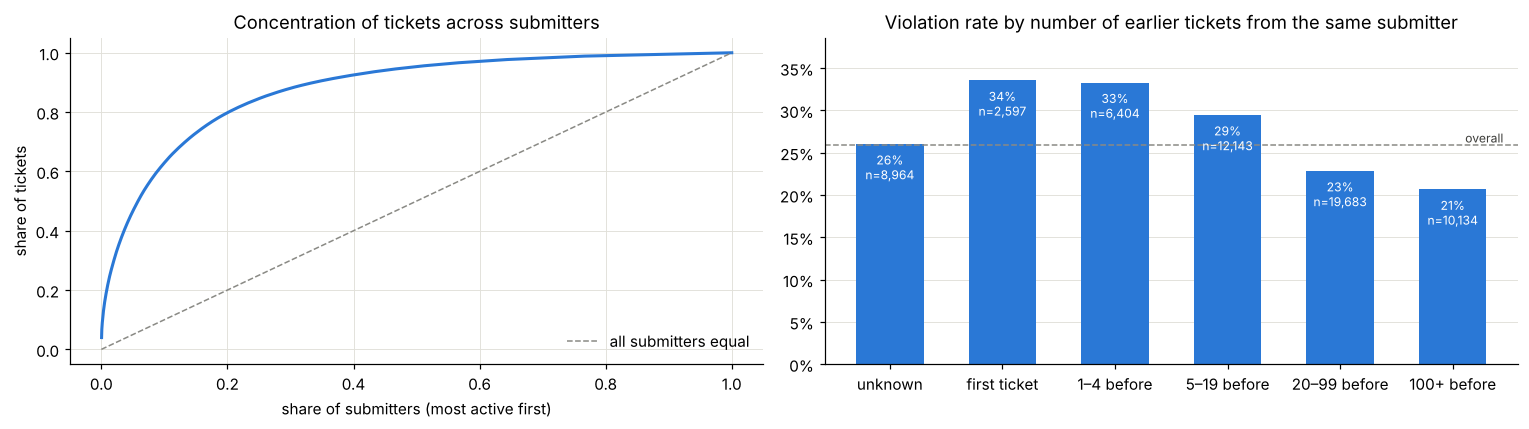

In [20]:
sub = df["SUBMITTED_BY_ID"].dropna()
counts = sub.value_counts().values
cum = np.cumsum(counts) / counts.sum()
share_sub = np.arange(1, len(counts) + 1) / len(counts)
print(f"submitters: {len(counts):,} | tickets without submitter: {df['SUBMITTED_BY_ID'].isna().mean():.1%}")
for k in [10, 100]:
    print(f"top {k} submitters open {cum[k - 1]:.1%} of the tickets with a known submitter")
print(f"submitters with at least 20 tickets: {(counts >= 20).sum():,}, covering {counts[counts >= 20].sum() / counts.sum():.1%} of those tickets")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(share_sub, cum, color=BLUE, lw=2)
axes[0].plot([0, 1], [0, 1], color=GRAY, lw=1, ls="--", label="all submitters equal")
axes[0].set_xlabel("share of submitters (most active first)"); axes[0].set_ylabel("share of tickets")
axes[0].set_title("Concentration of tickets across submitters"); axes[0].legend(frameon=False, loc="lower right")

bins = [-2, -0.5, 0.5, 4.5, 19.5, 99.5, np.inf]
names = ["unknown", "first ticket", "1–4 before", "5–19 before", "20–99 before", "100+ before"]
b = pd.cut(lab["submitter_prev_tickets"], bins, labels=names)
g = lab.groupby(b, observed=True)["viol"].agg(["mean", "size"])
axes[1].bar(g.index.astype(str), g["mean"], color=BLUE, width=0.6)
for x, (r, n) in enumerate(zip(g["mean"], g["size"])):
    axes[1].text(x, r - 0.01, f"{r:.0%}\nn={n:,}", ha="center", va="top", fontsize=8, color="white")
axes[1].axhline(overall, color=GRAY, lw=1, ls="--")
axes[1].set_ylim(0, g["mean"].max() * 1.15); axes[1].grid(axis="x", visible=False)
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[1].text(5.45, overall, "overall", fontsize=8, color=INK, va="bottom", ha="right")
axes[1].set_title("Violation rate by number of earlier tickets from the same submitter")
plt.tight_layout(); plt.show()

**Reading.** 2,662 submitters, very concentrated: the 100 most active ones open 41% of the tickets with a known submitter, and the 600 with at least 20 tickets cover 82%. The violation rate falls with the submitter's experience, from 34% on a first ticket to 21% after 100 tickets. This explains why `SUBMITTED_BY_ID` is the most important feature, and why the model has to be checked on new submitters, for whom this information does not exist.

### 8e. Link between the two targets
Each point is a closed ticket with an SLA: nominal deadline length against actual resolution time. Points above the diagonal took longer than the nominal deadline.

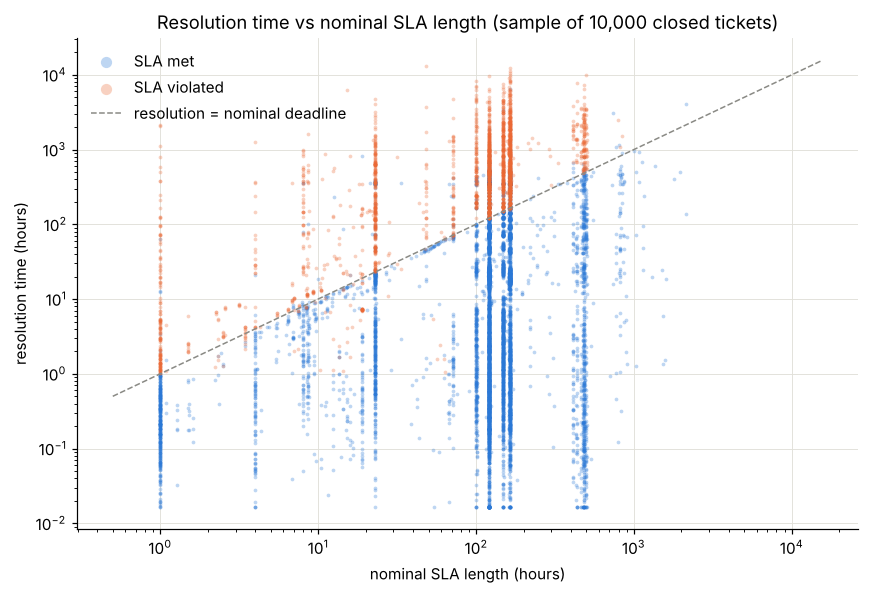

closed tickets above the diagonal: 28.8% | violation rate above: 83.5% | below: 0.9%


In [21]:
both = df[df["res_hours"].notna() & df["viol"].notna() & df["sla_nominal"].notna()]
smp = both.sample(min(10_000, len(both)), random_state=SEED)
fig, ax = plt.subplots(figsize=(8, 5.5))
for v, col, name in [(0, BLUE, "SLA met"), (1, ORANGE, "SLA violated")]:
    s = smp[smp["viol"] == v]
    ax.scatter(s["sla_nominal"].clip(lower=0.1), s["res_hours"].clip(lower=1 / 60), s=6, alpha=0.3,
               color=col, label=name, linewidths=0)
lim = [0.5, both["res_hours"].max()]
ax.plot(lim, lim, color=GRAY, lw=1, ls="--", label="resolution = nominal deadline")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("nominal SLA length (hours)"); ax.set_ylabel("resolution time (hours)")
ax.set_title("Resolution time vs nominal SLA length (sample of 10,000 closed tickets)")
ax.legend(frameon=False, markerscale=3, loc="upper left")
plt.tight_layout(); plt.show()

above = both["res_hours"] > both["sla_nominal"]
print(f"closed tickets above the diagonal: {above.mean():.1%} | violation rate above: "
      f"{both.loc[above, 'viol'].mean():.1%} | below: {both.loc[~above, 'viol'].mean():.1%}")

**Reading.** The vertical columns are the few standard SLA lengths. Closed tickets above the diagonal (28.8%) are violated in 83.5% of the cases, those below in 0.9%: a good prediction of the resolution time already gives most of the violation prediction. The two tasks are therefore linked, which is what the baseline notebook exploits (section 7) and what the survival model does in notebook 02.

## 9. Key takeaways for the modelling

1. **Target.** 25.9% of the labelled tickets are violated (2.9 : 1): evaluate with ROC-AUC and PR-AUC and set the threshold explicitly. The resolution time is extremely skewed, so the regression uses `log1p(hours)`.
2. **Temporal split.** Volume and ticket mix change over time, so train, validation and test are split by date.
3. **Missing values.** The submitter's missingness is structural (e-mail channel) and is kept as a category. The missingness of `END_DATE_UT`, `LAST_DONE_BY_ID` and `STATUS_EN` reveals the target, so these columns are never used as features.
4. **Distributions and outliers.** Several features have heavy tails, but the IQR outliers are a genuine long tail, not errors: they are kept, and handled with log transforms and tree models.
5. **Correlation.** No pair of features is redundant; each single feature is only weakly related to the violation, so a model that combines them is needed. The two targets are strongly linked (ρ = 0.63).
6. **Data errors.** 5.8% of the tickets have at least one hard error, mostly among violated and unlabelled tickets. The most important ones for the labels are the 66 impossible closing dates and the 9% of deadlines extended later (hence the nominal deadline).
7. **Questions for EasyVista:** the 14–15-day closures, tickets closed in less than a minute, never-closed tickets, the inconsistent `LAST_DONE_BY_ID`, and the tickets without origin.